# Aperture toy ring

In the previous notebook we built the lattice of the toy ring. Here we build an aperture model for the same line.

The important modelling choice is that the aperture model is not forced to have one pipe per lattice element. Instead we use a small set of reusable pipe descriptions:

- curved elliptical pipes for the arc bends;
- octagonal straight pipes for the quadrupoles;
- circular straight pipes for ordinary drifts;
- one aggregate chicane chamber installed from `chicane.start` to `chicane.end`;
- short transition pipes, or bellows, between neighbouring main pipes.

The construction below is deliberately split in two phases. First we build and place the main pipes. Then we inspect the gaps between those main pipes and place the required bellows. This keeps the aperture model tied to physical neighbours rather than to automatically generated drift names.

In [1]:
import warnings
import logging
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xtrack as xt

# Ignore annoying matplotlib warnings
logging.getLogger("matplotlib").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=RuntimeWarning)

env = xt.load('toy_ring.json')
ring = env["ring"]
table = ring.get_table()
survey = ring.survey()

Loading line from dict:   0%|          | 0/84 [00:00<?, ?it/s]

Done loading line from dict.           
Done loading line from dict.           


To build an aperture model we start with an `ApertureBuilder`. The builder stores reusable profiles and pipe blueprints, and later compiles them into the numerical aperture model.

In [2]:
builder = xt.ApertureBuilder(ring)

## Profiles

Profiles are transverse cross sections. Let's create the profiles used by the current model:

- `arc_ellipse` for the dipole chambers
- `quad_octagon` for quadrupoles
- `drift_circle` for ordinary drift space
- `ip_entry` and `ip_chamber` for the widened chicane insertion

In [3]:
builder.new_profile(
    "arc_ellipse",
    "Ellipse",
    half_major=0.055,
    half_minor=0.034,
    tol_r=0.001,
)
builder.new_profile(
    "quad_octagon",
    "Octagon",
    half_width=0.048,
    half_height=0.048,
    half_diagonal=0.050,
    tol_x=0.005,
    tol_y=0.001,
)
builder.new_profile(
    "drift_circle",
    "Circle",
    radius=0.040,
    tol_r=0.001,
)
builder.new_profile(
    "ip_entry",
    "RectEllipse",
    half_width=0.110,
    half_height=0.045,
    half_major=0.125,
    half_minor=0.055,
    tol_x=0.0015,
    tol_y=0.001,
)
builder.new_profile(
    "ip_chamber",
    "Racetrack",
    half_width=0.270,
    half_height=0.055,
    half_major=0.012,
    half_minor=0.010,
    tol_x=0.0015,
    tol_y=0.001,
    tol_r=0.001,
);

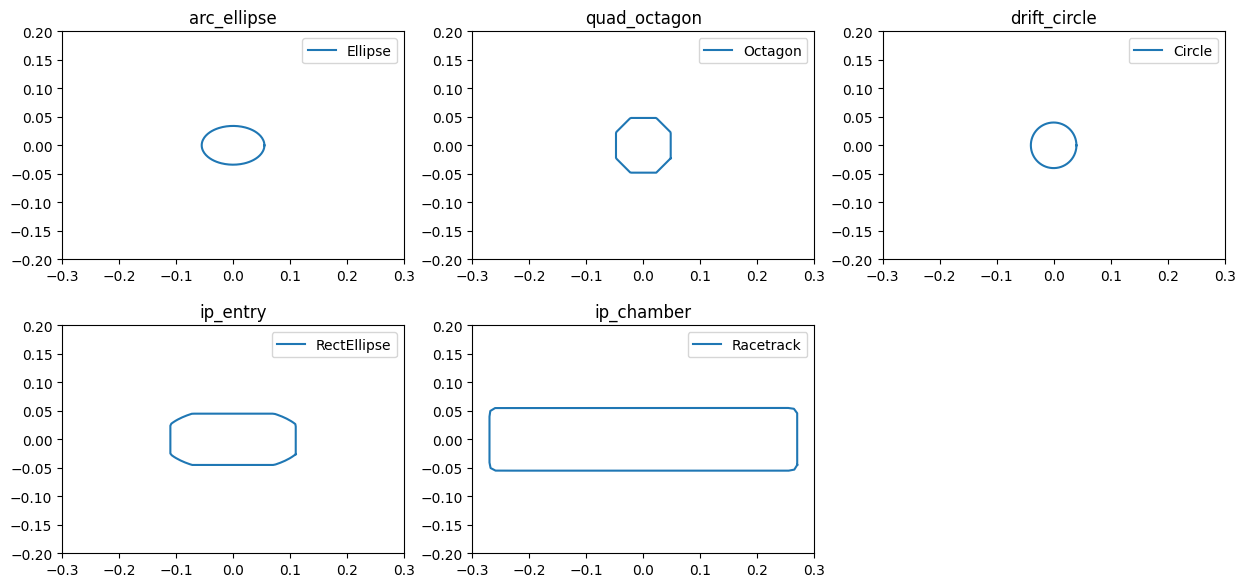

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
profile_names = ["arc_ellipse", "quad_octagon", "drift_circle", "ip_entry", "ip_chamber"]

for ax, profile_name in zip(axs.ravel(), profile_names):
    profile = builder.profiles[profile_name]
    profile.plot(ax=ax, label=type(profile.shape).__name__)
    ax.set_title(profile_name)
    ax.legend()
    ax.set_xlim(-0.3, 0.3)
    ax.set_ylim(-0.2, 0.2)

for ax in axs.ravel()[len(profile_names):]:
    ax.axis("off")

## Main pipes

A pipe blueprint is a longitudinal sequence of installed profiles. The same blueprint can later be installed many times at different survey references.

### Arc bend pipe

The bend pipe follows the bending radius of the `mb` element and uses the same elliptical profile at both ends.

In [5]:
l_mb = float(env["mb"].length)
ang_mb = float(env["ang_mb"])

arc_bend_pipe = builder.new_pipe(
    "arc_bend_pipe",
    curvature=ang_mb / l_mb,
    positions=[
        builder.place_profile("arc_ellipse", shift_s=0.0),
        builder.place_profile("arc_ellipse", shift_s=l_mb),
    ],
)

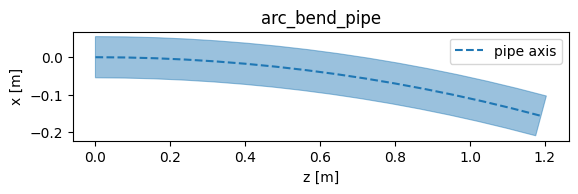

In [6]:
arc_bend_pipe.plot();

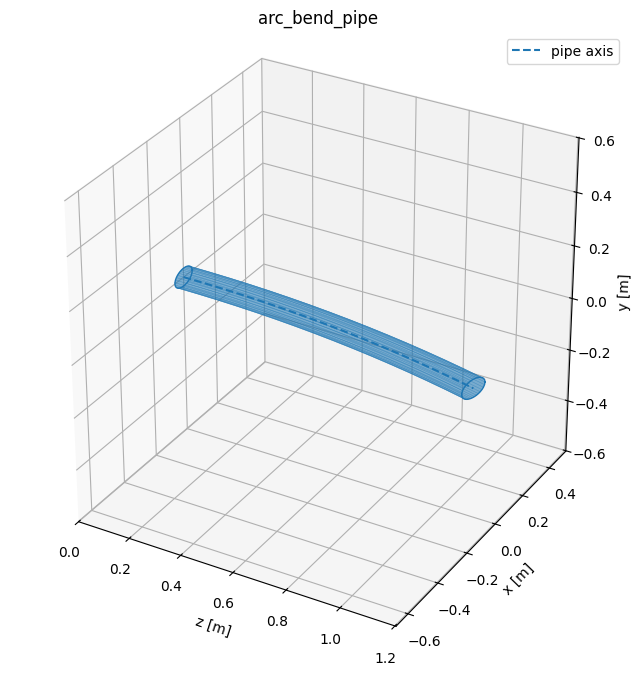

In [7]:
arc_bend_pipe.plot_3d(frame="curved");

### Quadrupole pipe

The quadrupole chamber is straight. We rotate the octagon slightly around the local pipe axis to make it visually distinct from an axis-aligned octagon.

In [8]:
l_mq = float(env["l_mq"])

quad_pipe = builder.new_pipe(
    "quad_pipe",
    positions=[
        builder.place_profile("quad_octagon", shift_s=0.0, rot_s_rad=np.deg2rad(22.5)),
        builder.place_profile("quad_octagon", shift_s=l_mq, rot_s_rad=np.deg2rad(22.5)),
    ],
)

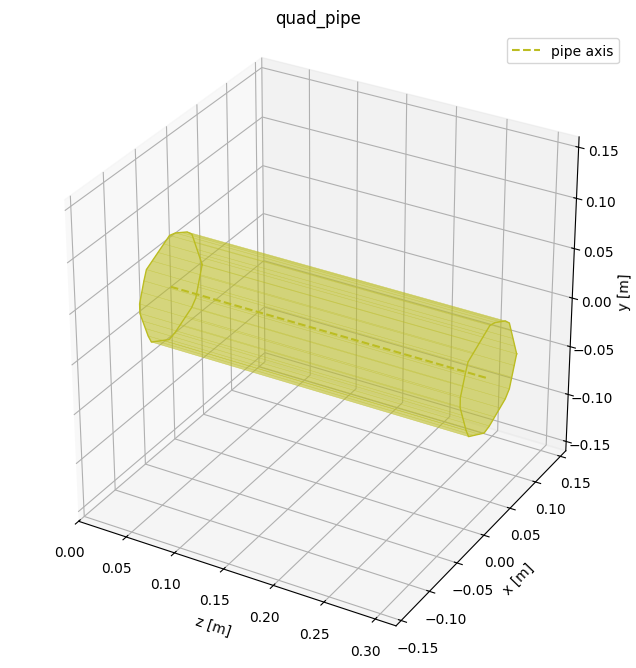

In [9]:
quad_pipe.plot_3d();

### Chicane pipe

The chicane is modelled as one aggregate insertion chamber rather than four separate bend chambers. The lattice bends the reference trajectory outwards and back; the aperture pipe is a straight insertion chamber installed from `chicane.start`.

The edge profiles are ordinary drift circles creating a smooth connection to the neighbouring pipes. Around the IP we widen the chamber and shift it outwards, which gives the insertion a plausible local experimental or utility volume while still connecting back to the circular machine pipe.

In [10]:
chicane_z0 = float(survey.rows["chicane.start"].Z[0])
chicane_z1 = float(survey.rows["chicane.end"].Z[0])
ip_z = float(survey.rows["ip"].Z[0])

chicane_pipe_length = chicane_z1 - chicane_z0
ip_s = ip_z - chicane_z0
chamber_width = 5.0

chicane_pipe = builder.new_pipe(
    "chicane_pipe",
    positions=[
        builder.place_profile("drift_circle", shift_s=0.0),
        builder.place_profile("ip_entry", shift_s=0.2),
        builder.place_profile("ip_chamber", shift_s=ip_s - chamber_width / 2, shift_x=0.15),
        builder.place_profile("ip_chamber", shift_s=ip_s + chamber_width / 2, shift_x=0.15),
        builder.place_profile("ip_entry", shift_s=chicane_pipe_length - 0.2),
        builder.place_profile("drift_circle", shift_s=chicane_pipe_length),
    ],
)


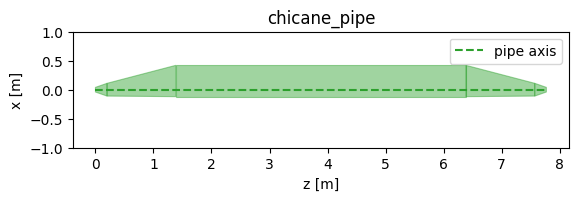

In [11]:
chicane_pipe.plot(plane="zx")
plt.ylim(-1, 1);

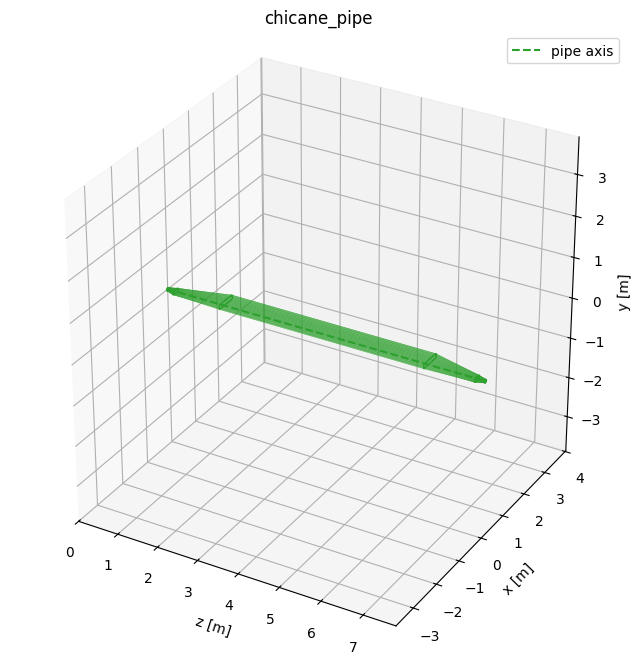

In [12]:
chicane_pipe.plot_3d();

### Straight-section drift pipe

The straight insertions between arcs use a circular drift pipe. We define the pipe around its centre (`shift_s=-s` and `shift_s=+s`) so that it can be installed directly at the midpoint markers `short.mid.*` and `utility.mid.*`.

In [13]:
sector_straight_length = chicane_pipe_length
straight_half_length = 0.5 * sector_straight_length - 1e-6

straight_pipe = builder.new_pipe(
    "straight_pipe",
    positions=[
        builder.place_profile("drift_circle", shift_s=-straight_half_length),
        builder.place_profile("drift_circle", shift_s=straight_half_length),
    ],
)

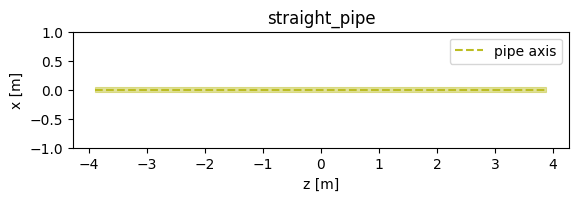

In [14]:
straight_pipe.plot()
plt.ylim(-1, 1);

## Install the main pipes

We now place all the main pipes. At this step, there are some gaps in the model, which we will address afterwards by constructing another set of pipes to function as bellows.

This is a short step: we collect the survey references for each family, then install each reusable pipe blueprint at all matching references.

In [15]:
mb_names = survey.rows[r'mb\..*'].name
quad_names = survey.rows[r'q[fd]\..*'].name
straight_names = survey.rows[r'(short.mid|utility.mid)\..*'].name

chicane_pipe.place("chicane_pipe", at="chicane.start")
arc_bend_pipe.place("arc_bend", at=mb_names)
quad_pipe.place("quad", at=quad_names)
straight_pipe.place("straight", at=straight_names)

len(builder.pipe_positions)

54

## Bellows

### Indentify the required transitions

After the main pipes are installed, the remaining aperture pieces are short transitions between neighbouring main pipes.

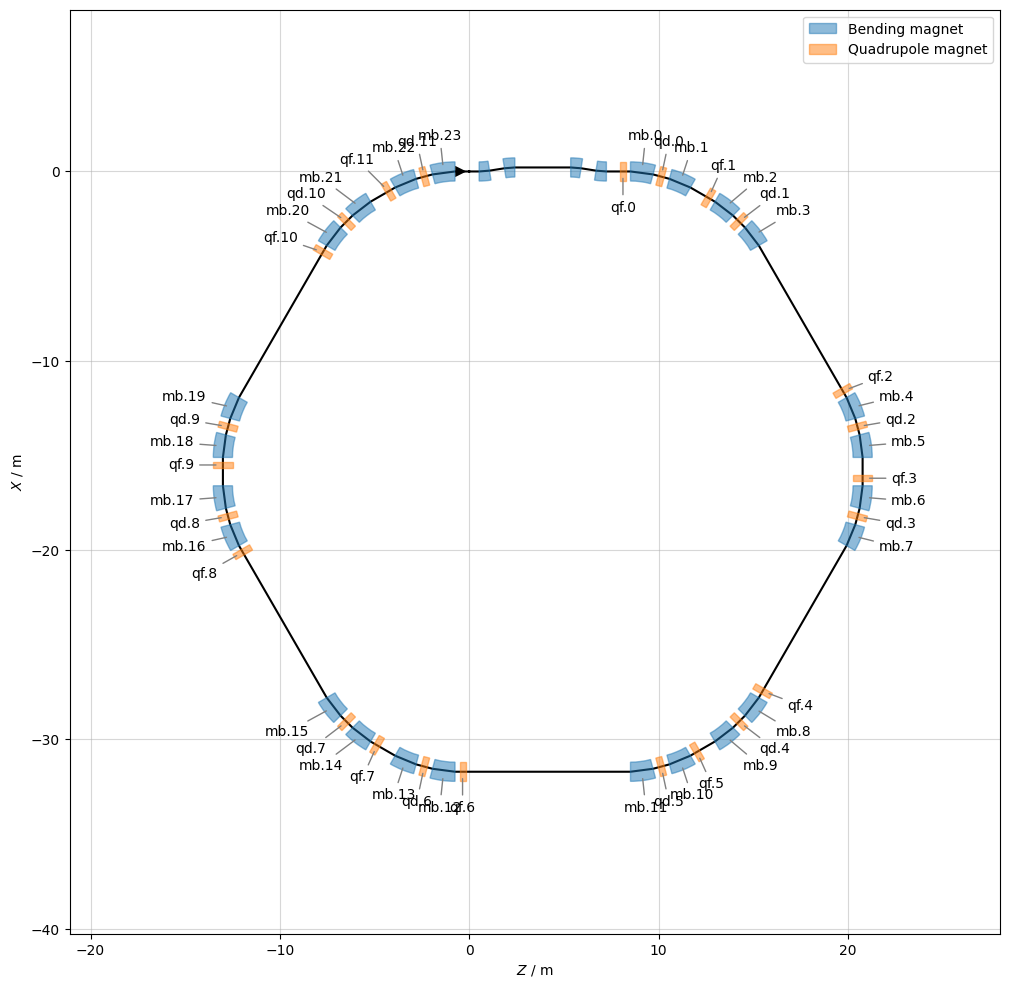

In [16]:
survey.plot(labels=[r'q[df]\..*', r'mb\..*'])
plt.gcf().set_figwidth(12)
plt.gcf().set_figheight(12)

Zooming into one cell of the arc, we can identify what bellows are needed:

SurveyTable: 10 rows, 3 cols
name                   s        length
||drift_1              0          0.19
qf                  0.19          0.32
||drift_2           0.51      0.238283
mb::0           0.748283       1.20343
||drift_3        1.95172      0.288283
qd                  2.24          0.32
||drift_4           2.56      0.288283
mb::1            2.84828       1.20343
||drift_5        4.05172      0.748283
_end_point           4.8             0

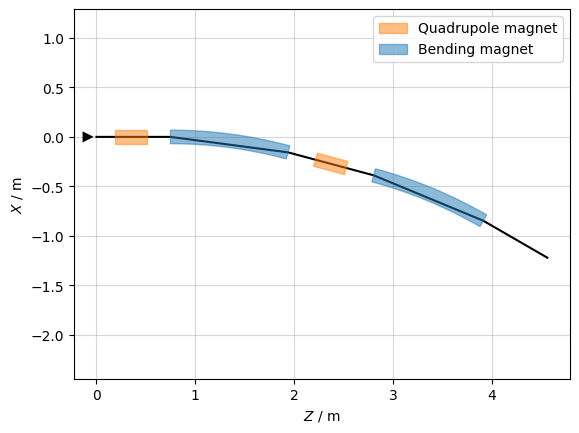

In [17]:
cell_sv = env['arc_cell'].survey()
cell_sv.plot()

cell_sv.cols['name', 's', 'length']

In the surveys above we can see that all the arcs, and all the straight sections (not counting the chicane) are the same.

Since we have placed pipes at all of the magnets, and at the chicane, the remaning parts of the aperture model that we still need to cover are the transitions between:
- chicane end/long straight section to `qf` of length 0.19 m
- `qf` and `mb` of length 0.238 m
- `mb` and `qd` of length 0.288 m (works in both directions)
- `mb` and the drift pipe

We will also need to construct a suitable pipe for the short straight section in the middle of the arc.

Let's collect some values:

In [18]:
edge_to_qf_len = cell_sv.rows[0].length[0]
qf_to_mb_len = cell_sv.rows['qf>>1'].length[0]
mb_to_qd_len = cell_sv.rows['mb::0>>1'].length[0]
qd_to_mb_len = cell_sv.rows['qd>>1'].length[0]
mb_to_edge_len = cell_sv.rows['mb::1>>1'].length[0]
mb_to_drift_len = edge_to_qf_len
edge_drift_len = mb_to_edge_len - mb_to_drift_len

assert np.isclose(mb_to_qd_len, qd_to_mb_len, rtol=0, atol=1e-6)
assert edge_drift_len > 0

print(f'- bellow from cell/straight edge to qf: {edge_to_qf_len} m')
print(f'- bellow from qf to mb: {qf_to_mb_len} m')
print(f'- bellow from mb to qd and qd to mb: {mb_to_qd_len} m')
print(f'- interface from mb to cell/straight edge: {mb_to_edge_len} m')
print(f'  - first {mb_to_drift_len} m transition from bend ellipse to drift circle')
print(f'  - remaining {edge_drift_len} m as circular drift pipe')


- bellow from cell/straight edge to qf: 0.18999999999999997 m
- bellow from qf to mb: 0.2382830954929256 m
- bellow from mb to qd and qd to mb: 0.2882830954929252 m
- interface from mb to cell/straight edge: 0.7482830954929254 m
  - first 0.18999999999999997 m transition from bend ellipse to drift circle
  - remaining 0.5582830954929254 m as circular drift pipe


### Construct the bellow pipes

In [19]:
edge_qf_bellow = builder.new_pipe(
    'edge_qf_bellow',
    positions=[
        builder.place_profile('drift_circle', shift_s=0),
        builder.place_profile('quad_octagon', shift_s=edge_to_qf_len),
    ],
)

In [20]:
qf_to_mb_bellow = builder.new_pipe(
    'qf_to_mb_bellow',
    positions=[
        builder.place_profile('quad_octagon', shift_s=0),
        builder.place_profile('arc_ellipse', shift_s=qf_to_mb_len),
    ],
)

In [21]:
mb_to_qd_bellow = builder.new_pipe(
    'mb_to_qd_bellow',
    positions=[
        builder.place_profile('arc_ellipse', shift_s=0),
        builder.place_profile('quad_octagon', shift_s=mb_to_qd_len, rot_s_rad=np.deg2rad(22.5)),
    ],
)

In [22]:
mb_to_edge_iface = builder.new_pipe(
    'mb_to_edge_iface',
    positions=[
        builder.place_profile('arc_ellipse', shift_s=0),
        builder.place_profile('drift_circle', shift_s=0.19),
        builder.place_profile('drift_circle', shift_s=mb_to_edge_len),
    ],
)

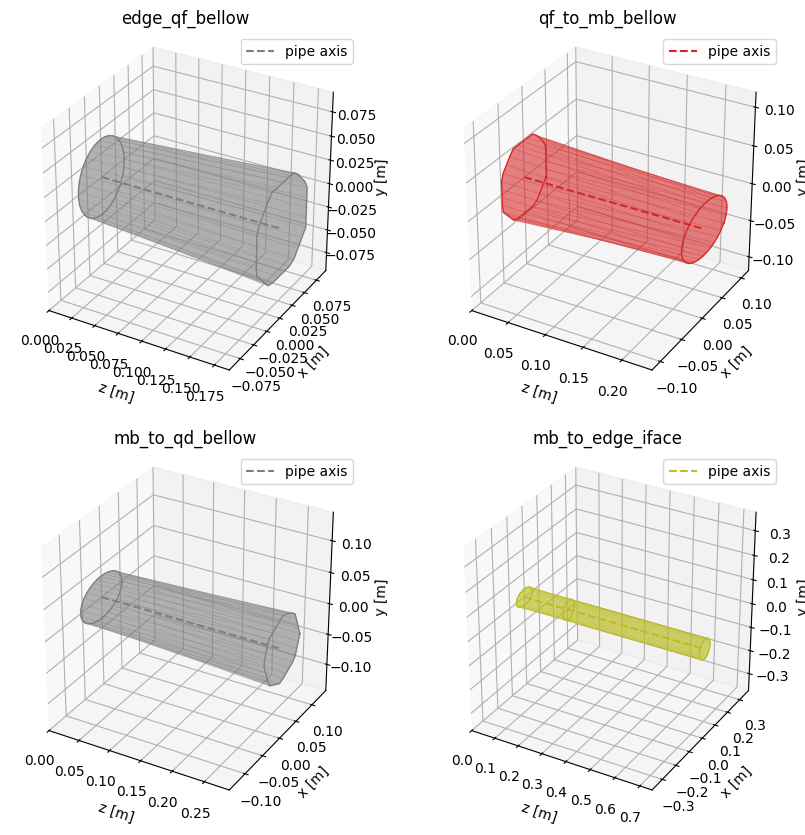

In [23]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10), subplot_kw={'projection': '3d'})
transition_names = ['edge_qf_bellow', 'qf_to_mb_bellow', 'mb_to_qd_bellow', 'mb_to_edge_iface']

for ax, name in zip(axs.ravel(), transition_names):
    pipe = builder.pipes[name]
    pipe.plot_3d(ax=ax)
    ax.set_title(name)
    ax.legend()

for ax in axs.ravel()[len(profile_names):]:
    ax.axis("off")

### Install the bellows

Now that the few transition pipe blueprints exist, installing them is mechanical. We use the physical neighbours as anchors:

- `edge_qf_bellow` ends at the start of each `qf`, so we place it at `qf@start` with a negative longitudinal shift;
- `qf_to_mb_bellow` starts at `qf@end`;
- `mb_to_qd_bellow` starts at the end of the first bend in each cell;
- the same `mb_to_qd_bellow` is reused backwards between `qd` and the second bend by placing it at `mb@start` with `rot_y_rad=np.pi`;
- `mb_to_edge_iface` starts at the end of the second bend in each cell and carries the pipe to the next cell edge, straight section, or the chicane boundary.

No generated drift names are needed here.

In [24]:
qf_names = list(survey.rows[r'qf\..*'].name)
qd_names = list(survey.rows[r'qd\..*'].name)
mb_names = list(survey.rows[r'mb\..*'].name)

mb_to_qd_names = mb_names[0::2]
qd_to_mb_names = mb_names[1::2]

assert len(qf_names) == len(qd_names) == len(mb_to_qd_names) == len(qd_to_mb_names)

edge_qf_bellow.place(
    'edge_qf_bellow',
    at=[f'{name}@start' for name in qf_names],
    shift_z=-edge_to_qf_len,
)
qf_to_mb_bellow.place(
    'qf_to_mb_bellow',
    at=[f'{name}@end' for name in qf_names],
)
mb_to_qd_bellow.place(
    'mb_to_qd_bellow',
    at=[f'{name}@end' for name in mb_to_qd_names],
)
mb_to_qd_bellow.place(
    'qd_to_mb_bellow',
    at=[f'{name}@start' for name in qd_to_mb_names],
    rot_y_rad=np.pi,
)
mb_to_edge_iface.place(
    'mb_to_edge_iface',
    at=[f'{name}@end' for name in qd_to_mb_names],
)

len(builder.pipe_positions)


114

## Build and inspect the aperture model

At this point the builder contains all profiles, pipe blueprints, and installed pipe positions. The final step compiles the aperture model and wraps it in the high-level `Aperture` object.

In [25]:
aperture = xt.Aperture(line=ring, model=builder.build(), num_profile_points=64, s_tol=1e-6)

Building cross-sections:   0%|          | 0/244 [00:00<?, ?it/s]

### The pipe table

The most basic way to inspect the model is to look at the pipe table, which lists all of the pipes and their locations:

In [26]:
pipe_table = aperture.get_pipe_table()
pipe_table

Table: 114 rows, 9 cols
name               pipe_name        survey_reference       s_start         s_end        length ...
chicane_pipe       chicane_pipe     chicane.start                0           7.8           7.8
edge_qf_bellow.0   edge_qf_bellow   qf.0                       7.8          7.99          0.19
quad.0             quad_pipe        qf.0                      7.99          8.31          0.32
qf_to_mb_bellow.0  qf_to_mb_bellow  qf.0                      8.31       8.54828      0.238283
arc_bend.0         arc_bend_pipe    mb.0                   8.54828       9.75172       1.20343
mb_to_qd_bellow.0  mb_to_qd_bellow  mb.0                   9.75172         10.04      0.288283
quad.1             quad_pipe        qd.0                     10.04         10.36          0.32
qd_to_mb_bellow.0  mb_to_qd_bellow  mb.1                     10.36       10.6483      0.288283
arc_bend.1         arc_bend_pipe    mb.1                   10.6483       11.8517       1.20343
mb_to_edge_iface.0 mb_

The columns of the pipe table are:

In [27]:
pipe_table.cols

ColView: name pipe_name survey_reference s_start s_end length s_span_start s_span_end span

In particular:
- `s_start` and `s_end` refer to the placement of the most extreme profiles of the pipe along the survey, where the profile's $s$-position is calculated as the intersection of the profile plane with the survey curve
- `s_span_start` and `s_span_end` refer, similarly, to the most extreme $s$-span positions of the pipe's profiles, where this is calculated by looking at all profile polygons placed in the survey frame, projecting their points onto the survey curve, and taking the most extreme values of $s$ obtained this way
- `length` refers simply to `s_end - s_start`, while `span` refers to `s_span_end - s_span_start`

If all the profiles are installed orthogonally to the survey, the `s_span_...` and `s_...` quantities are equal.

### The aperture bounds table

We can investigate the positioning of all the profiles of all the pipes using the bounds table:

In [28]:
bounds_table = aperture.get_bounds_table()
bounds_table

Table: 244 rows, 8 cols
name                pipe_name      profile_name             s       s_start         s_end ...
chicane_pipe::0     chicane_pipe   drift_circle             0             0             0
chicane_pipe::1     chicane_pipe   ip_entry               0.2           0.2           0.2
chicane_pipe::2     chicane_pipe   ip_chamber         1.39179       1.35852         1.443
chicane_pipe::3     chicane_pipe   ip_chamber         6.40821         6.357       6.44148
chicane_pipe::4     chicane_pipe   ip_entry               7.6           7.6           7.6
chicane_pipe::5     chicane_pipe   drift_circle           7.8           7.8           7.8
edge_qf_bellow.0::0 edge_qf_bellow drift_circle           7.8           7.8           7.8
edge_qf_bellow.0::1 edge_qf_bellow quad_octagon          7.99          7.99          7.99
quad.0::0           quad_pipe      quad_octagon          7.99          7.99          7.99
quad.0::1           quad_pipe      quad_octagon          8.31          8

In [29]:
bounds_table.cols

ColView: name pipe_name profile_name s s_start s_end shape shape_param

Here it's the `s` values that determine the `s_start` and `s_end` of the pipe table, whereas `s_start` and `s_end` values determine the span.

We can see that for the chicane pipe, the first two and the last two profiles have the same `s`, `s_start`, and `s_end`, and that this is true for most of the other profiles installed in the model.

However, the 3rd and 4rd profiles of the chicane pipe correspond at the location somewhere inside of the chicane bends, and so they are not installed orthogonally to the survey: this is reflected in the fact that `s`, `s_start`, and `s_end` values differ, and in particular, since `s` falls between the other two, we can deduce that the survey correctly passes though the profile.

In fact, this is one of the checks conducted when the model is built: all installed profiles must encompass the survey.

### Floor plot

The most basic plot is the floor plot of the aperture model. Below we overlay the survey on top as well:

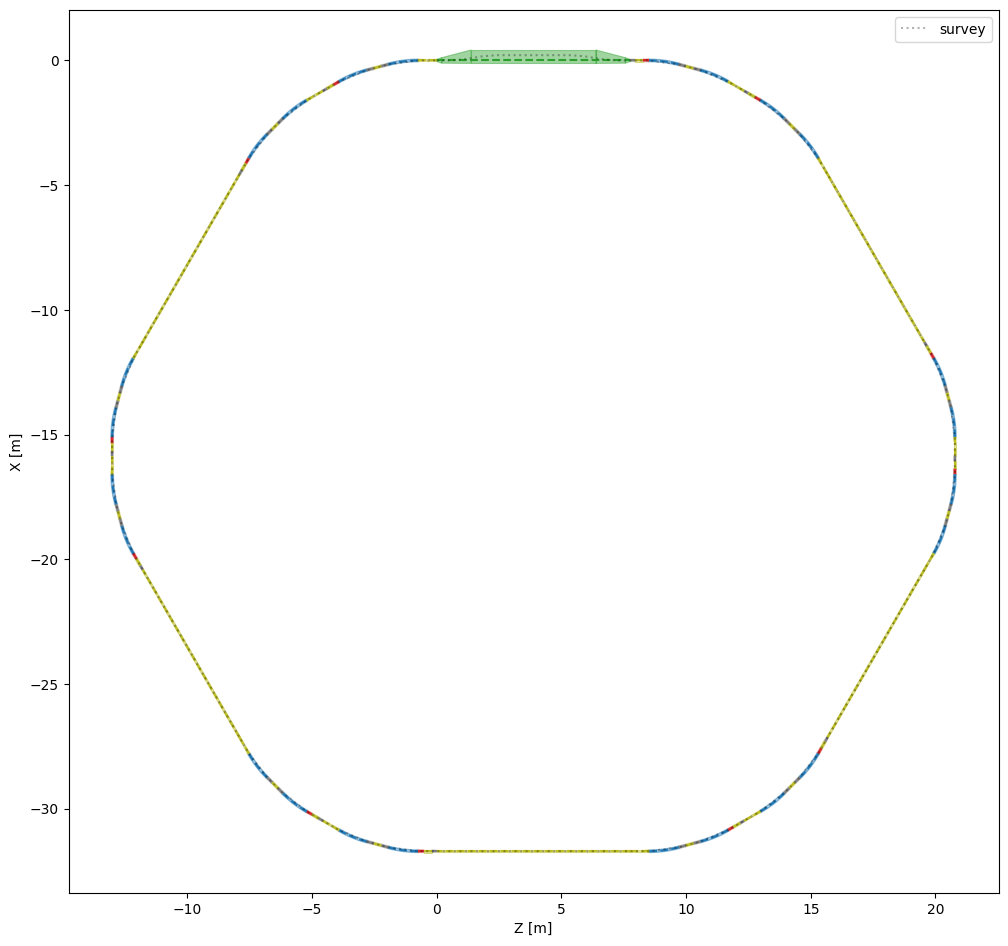

In [30]:
ax = aperture.plot_floor_projection()
ax.plot(survey.Z, survey.X, c='black', alpha=0.3, linestyle=':', label='survey')

ax.legend()
ax.set_aspect('equal')

plt.gcf().set_figwidth(12)
plt.gcf().set_figheight(12)

We can choose to plot around an arbitrary point using the `origin` parameter, and we can specify the range of the plot in $s$ using `s_range`:

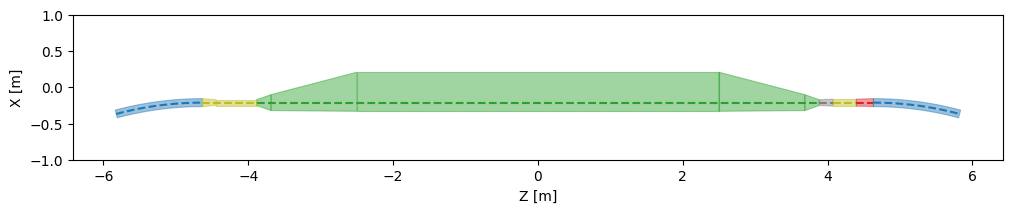

In [31]:
ax = aperture.plot_floor_projection(origin=3.9, s_range=(-5, 5))
ax.set_aspect('equal')
ax.set_ylim(-1, 1)
plt.gcf().set_figwidth(12)

The `origin` parameter also accepts pipe position names (note that the shapes are always plotted whole):

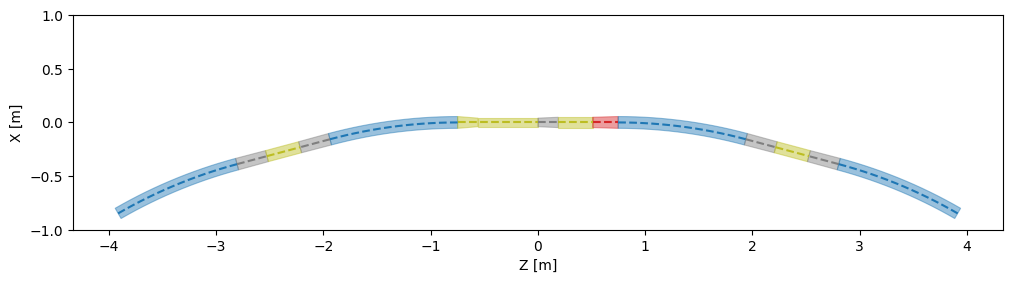

In [32]:
ax = aperture.plot_floor_projection(origin='edge_qf_bellow.3', s_range=(-3, 3))
ax.set_aspect('equal')
ax.set_ylim(-1, 1)
plt.gcf().set_figwidth(12);

### Extents plot

The second useful type of plot is seeing the aperture limitation from the point of view of the beam.

For this we can use the `plot_extents` function, which requires a parameter `s_positions`: the $s$ positions at which we will sample the model to compute the cross section of the aperture model seen by the beam.

The convenience function `s_around_transitions` allows us to generate a list of $s$ positions with a given resolution, but also adding $s$ positions where the geometry of the model might change. This way, we can capture many of the points of interest of the model.

The extents plot shows the beam envelope at the maximum permissible size, but this can be tweaked using the `sigmas` parameter. The dashed line on the plot includes the aperture tolerances specified in the profile definitions (and interpolated where necessary).

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]

Computing sigmas: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

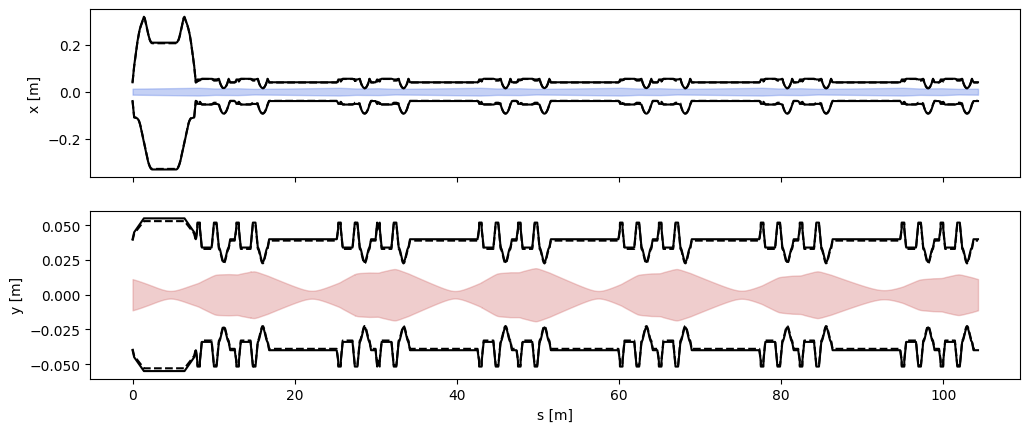

In [33]:
s_sample = aperture.s_around_transitions(resolution=0.1)
aperture.plot_extents(s_positions=s_sample)
plt.gcf().set_figwidth(12);

For example, we can see the beam at $1\sigma$ between $s = 20\,\text{m}$ and $s = 40\,\text{m}$ like so:

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing beam envelopes: 100%
Interpolating profiles: 100%

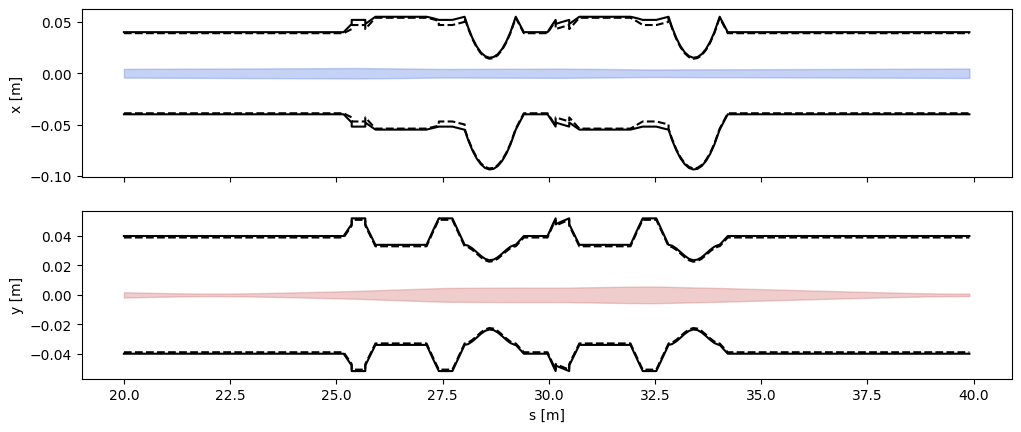

In [34]:
s_sample = aperture.s_around_transitions(resolution=0.1, s_range=(20, 40))
aperture.plot_extents(s_positions=s_sample, sigmas=1)
plt.gcf().set_figwidth(12);

### Save the model to JSON

In [35]:
aperture.to_json('aperture_model.json')